
# Random Forest Classifier (80/20 split) — CUB-200-2011 Tabular Attributes

This is the **80/20 split** version of [`randomForest.ipynb`](randomForest.ipynb). The code and protocol are the same, but it trains on the stratified 80/20 split (`is_train_80`, built in `dataPrep.ipynb` §8):

| | Official (`is_train`) | 80/20 (`is_train_80`) |
|---|---|---|
| Train | 5,994 (29–30 per species) | 9,430 (33–48 per species) |
| Test | 5,794 (11–30 per species) | 2,358 (8–12 per species) |

**Input:** the feature files written by [`dataPrep.ipynb`](dataPrep.ipynb) (run that first).
**Protocol:** the same as [`decisionTree_80_20.ipynb`](decisionTree_80_20.ipynb), so the two 80/20 models are directly comparable:
- grid search with stratified 5-fold CV on the **training portion only**, using the same folds (`random_state = 42`), with no separate validation set;
- the test set is used once, at the end;
- everything is re-tuned from scratch on this split.

For the one-at-a-time validation curves we use the forest's **out-of-bag (OOB) score**. Each tree is scored on the roughly 37% of training images left out of its bootstrap sample. This gives an honest out-of-sample estimate from a single fit, without touching the test set. It is slightly pessimistic, because each image is scored by only the ~37% of trees that did not see it, so OOB is used to compare settings, while CV is used for the final model choice.

**Differences from the official-split notebook:**
- `class_weight` is added to the grid, because the 80/20 training classes are uneven (33–48 images).
- §8 compares against the decision tree tuned on the **80/20** split.
- A new §11 compares with the official split and separates the effect of *more training data* from the effect of *a different test set*.

| Step | Section |
|---|---|
| Baseline (default forest) | 2 |
| Number of trees (OOB curve) | 3 |
| Validation curves (OOB) | 4 |
| Grid search (5-fold CV) | 5 |
| Feature variant comparison (A / B / C) | 6 |
| Final test evaluation | 7 |
| Comparison with the 80/20 decision tree | 8 |
| Error analysis | 9 |
| Feature importance | 10 |
| Comparison with the official split | 11 |


## 1. Setup

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix

RANDOM_STATE = 42
SPLIT = 'is_train_80'  # stratified 80/20 split; randomForest.ipynb uses the official 'is_train'
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train', 'is_train_80']  # never used as features

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}

def load_variant(name):
    """Return X_train, y_train, X_test, y_test for feature variant A, B or C."""
    path = DATA / f'cub_features_{name}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    df = pd.read_csv(path)
    features = [c for c in df.columns if c not in META_COLS]
    train, test = df[df[SPLIT] == 1], df[df[SPLIT] == 0]
    return train[features], train.class_id, test[features], test.class_id

def oob_score(X, y, **params):
    rf = RandomForestClassifier(oob_score=True, random_state=RANDOM_STATE, n_jobs=-1, **params)
    return rf.fit(X, y).oob_score_

X_train, y_train, X_test, y_test = load_variant('A')
class_names = pd.read_csv(DATA / 'cub_features_A.csv', usecols=['class_id', 'class_name']) \
                .drop_duplicates().set_index('class_id').class_name.sort_index()

print('train', X_train.shape, '| test', X_test.shape, '| classes', y_train.nunique())

train (9430, 312) | test (2358, 312) | classes 200


## 2. Baseline: default Random Forest

The defaults are 100 trees, `max_features='sqrt'` (about 18 of the 312 features tried at each split), and fully grown trees. This baseline is the reference point that tuning has to beat. It is evaluated with the same 5-fold CV as the 80/20 decision tree, so the two baselines are directly comparable.

In [2]:
baseline = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
cv_base = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)

print(f"train accuracy (CV folds): {cv_base['train_accuracy'].mean():.3f}")
print(f"CV accuracy:               {cv_base['test_accuracy'].mean():.3f} ± {cv_base['test_accuracy'].std():.3f}")
print(f"CV macro-F1:               {cv_base['test_f1_macro'].mean():.3f} ± {cv_base['test_f1_macro'].std():.3f}")

train accuracy (CV folds): 0.999
CV accuracy:               0.449 ± 0.008
CV macro-F1:               0.431 ± 0.007


## 3. How many trees?

Adding trees never causes overfitting. It only reduces variance, until the accuracy plateaus. So `n_estimators` is not tuned like the other hyperparameters. The question is simply how many trees are needed before accuracy stops improving. We grow one forest incrementally (`warm_start`) and track the OOB accuracy.

**Two tree counts are used, deliberately:**
- **Final model: the smallest count within 0.25 points of the best OOB score** (next cell). Beyond that point, extra trees only add runtime. 0.25 points is well below the CV fold noise (about 1 point), so the improvement given up is negligible.
- **Grid search and validation curves: 300 trees.** These need hundreds of fits, and 300 trees is already close to the plateau. More trees raise every configuration's score by a similar amount, so the *ranking* of configurations, which is all the search needs, is unaffected.

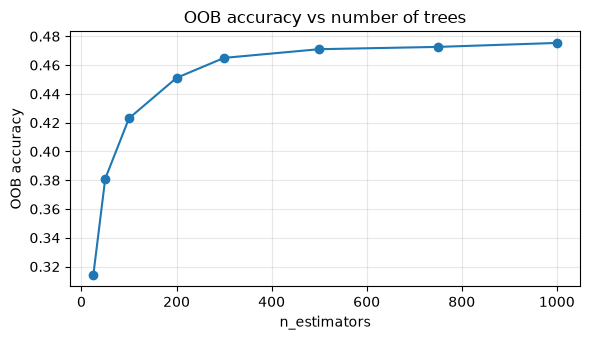

,25,50,100,200,300,500,750,1000
OOB accuracy,0.3142,0.381,0.423,0.4511,0.465,0.471,0.4726,0.4754


In [3]:
tree_counts = [25, 50, 100, 200, 300, 500, 750, 1000]
oob_by_trees = {}
rf = RandomForestClassifier(warm_start=True, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)
for n in tree_counts:
    rf.set_params(n_estimators=n).fit(X_train, y_train)
    oob_by_trees[n] = rf.oob_score_

oob_by_trees = pd.Series(oob_by_trees, name='OOB accuracy')
fig, ax = plt.subplots(figsize=(6, 3.5))
oob_by_trees.plot(ax=ax, marker='o')
ax.set(title='OOB accuracy vs number of trees', xlabel='n_estimators', ylabel='OOB accuracy')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
oob_by_trees.round(4).to_frame().T

In [4]:
# Smallest forest within 0.25 percentage points of the best OOB score: more trees beyond this only add runtime
FINAL_N_ESTIMATORS = int(oob_by_trees[oob_by_trees >= oob_by_trees.max() - 0.0025].index.min())
SEARCH_N_ESTIMATORS = 300  # used inside the grid search to keep runtime manageable
print('final n_estimators:', FINAL_N_ESTIMATORS)

final n_estimators: 1000


## 4. Validation curves (OOB)

We vary one hyperparameter at a time (300 trees, other settings at their defaults), for both split criteria, to find the region worth grid-searching. These are the forest's main controls:
- `max_features`: how many features each split considers. Fewer features make the trees more different from each other; more make each tree stronger.
- `min_samples_leaf` and `max_depth`: how far each tree is allowed to grow.

OOB is used here because it needs one fit per point instead of five.

**Reading the curves** (the same shape as on the official split, about 3 points higher overall):
- Gini beats entropy by about 6 points at every setting.
- `max_features` peaks at `sqrt` (about 18 features, OOB 0.465) and falls off on both sides: `log2` is too few, and 0.3 or more makes the trees too similar.
- `min_samples_leaf` is best at 1 and declines steadily from there. With more training images, fully grown trees benefit slightly more than on the official split, where 1 and 2 were level.
- `max_depth` hurts below about 20 and is flat from 20 upwards.

So the grid ranges used on the official split still cover the useful region and are kept unchanged.

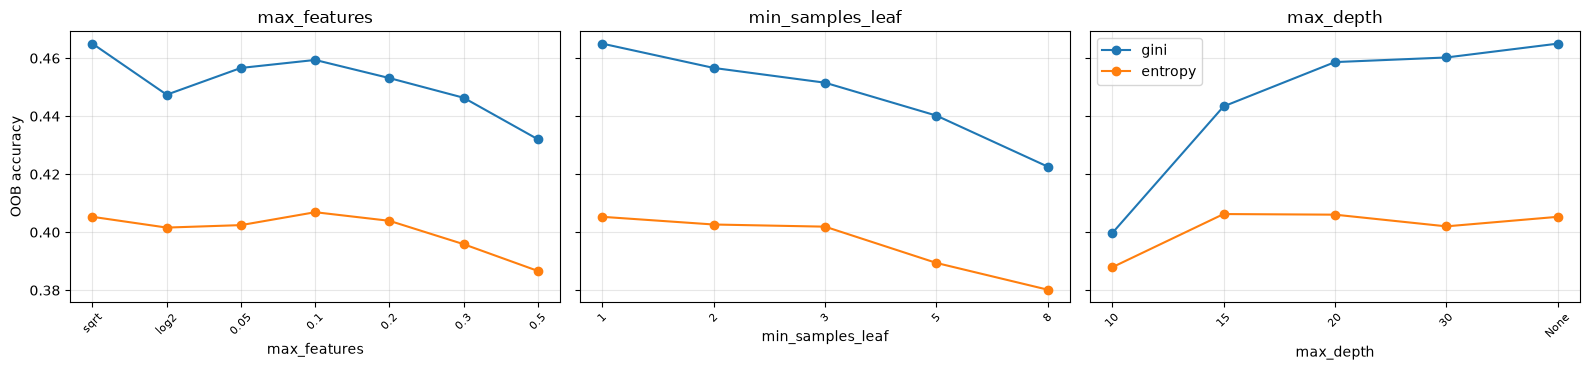

55s


max_features         min_samples_leaf         max_depth        
             gini entropy             gini entropy      gini entropy
sqrt       0.4650  0.4053              NaN     NaN       NaN     NaN
log2       0.4474  0.4016              NaN     NaN       NaN     NaN
0.05       0.4566  0.4024              NaN     NaN       NaN     NaN
0.1        0.4594  0.4069              NaN     NaN       NaN     NaN
0.2        0.4531  0.4039              NaN     NaN       NaN     NaN
0.3        0.4463  0.3959              NaN     NaN       NaN     NaN
0.5        0.4320  0.3866              NaN     NaN       NaN     NaN
1             NaN     NaN           0.4650  0.4053       NaN     NaN
2             NaN     NaN           0.4566  0.4027       NaN     NaN
3             NaN     NaN           0.4515  0.4019       NaN     NaN
5             NaN     NaN           0.4402  0.3894       NaN     NaN
8             NaN     NaN           0.4226  0.3802       NaN     NaN
10            NaN     NaN              NaN     NaN    0.3997  0.3879
15            NaN     NaN              NaN     NaN    0.4434  0.4063
20            NaN     NaN              NaN     NaN    0.4586  0.4060
30            NaN     NaN              NaN     NaN    0.4602  0.4020
None          NaN     NaN              NaN     NaN    0.4650  0.4053

In [5]:
curves = {
    'max_features': ['sqrt', 'log2', 0.05, 0.1, 0.2, 0.3, 0.5],
    'min_samples_leaf': [1, 2, 3, 5, 8],
    'max_depth': [10, 15, 20, 30, None],
}

t0 = time.time()
fig, axes = plt.subplots(1, len(curves), figsize=(16, 3.8), sharey=True)
curve_tables = {}
for ax, (param, values) in zip(axes, curves.items()):
    table = {}
    for criterion, colour in [('gini', 'tab:blue'), ('entropy', 'tab:orange')]:
        scores = [oob_score(X_train, y_train, n_estimators=SEARCH_N_ESTIMATORS,
                            criterion=criterion, **{param: v}) for v in values]
        table[criterion] = scores
        ax.plot(range(len(values)), scores, 'o-', color=colour, label=criterion)
    curve_tables[param] = pd.DataFrame(table, index=[str(v) for v in values]).round(4)
    ax.set_xticks(range(len(values)), [str(v) for v in values], rotation=45, fontsize=8)
    ax.set(title=param, xlabel=param)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('OOB accuracy')
axes[-1].legend()
plt.tight_layout()
plt.show()
print(f'{time.time() - t0:.0f}s')
pd.concat(curve_tables, axis=1)

## 5. Grid search (variant A, 5-fold CV)

**How the ranges were chosen from §4** (the same ranges as on the official split, which the curves above support):
- `max_features` ∈ {`sqrt`, 0.1, 0.2}: the peak region.
- `min_samples_leaf` ∈ {1, 2}: values of 3 or more were already worse.
- `max_depth` ∈ {30, `None`}: depth only matters below 15, so we only check whether capping very deep trees helps.
- The split criterion is kept in the grid even though entropy looked worse, so the final choice is justified by CV.
- `class_weight` ∈ {`None`, `'balanced_subsample'`} (new for this split). `'balanced_subsample'` reweights species inversely to their counts *within each tree's bootstrap sample*, so species with 48 training images don't outvote species with 33. Testing both lets CV decide whether the mild imbalance matters. (For the single tree it made no measurable difference.)

That gives 48 combinations × 5 folds, scored with the **same folds as the 80/20 decision tree**.

**Implementation choices:**
- **Parallelism:** `n_jobs=-1` is set on the grid search and `n_jobs=1` on each forest. This runs one forest per CPU core, instead of nesting parallel jobs, which would oversubscribe the cores.
- **`refit=False`:** the grid search doesn't refit the best model itself. It is refit by hand in §7 with the final tree count from §3 rather than the 300 used for searching.

In [6]:
PARAM_GRID = {
    'criterion': ['gini', 'entropy'],
    'max_features': ['sqrt', 0.1, 0.2],
    'min_samples_leaf': [1, 2],
    'max_depth': [30, None],
    'class_weight': [None, 'balanced_subsample'],
}

def grid_search(X, y):
    rf = RandomForestClassifier(n_estimators=SEARCH_N_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=1)
    gs = GridSearchCV(rf, PARAM_GRID, cv=CV, scoring=SCORING, refit=False, n_jobs=-1)
    return gs.fit(X, y)

def best_row(gs):
    i = int(np.argmin(gs.cv_results_['rank_test_accuracy']))
    r = gs.cv_results_
    return {'cv_accuracy': r['mean_test_accuracy'][i], 'cv_acc_std': r['std_test_accuracy'][i],
            'cv_f1_macro': r['mean_test_f1_macro'][i], **r['params'][i]}

def top_results(gs, n=8):
    res = pd.DataFrame(gs.cv_results_)
    cols = ['param_' + p for p in PARAM_GRID] + ['mean_test_accuracy', 'std_test_accuracy', 'mean_test_f1_macro']
    return res.sort_values('rank_test_accuracy')[cols].head(n).round(4)

t0 = time.time()
gs_A = grid_search(X_train, y_train)
print(f"{len(gs_A.cv_results_['params'])} combinations x {CV.get_n_splits()} folds in {time.time() - t0:.0f}s")
top_results(gs_A)

/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


48 combinations x 5 folds in 229s


,param_criterion,param_max_features,param_min_samples_leaf,param_max_depth,param_class_weight,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro
30,gini,sqrt,1,None,balanced_subsample,0.4726,0.0063,0.4531
6,gini,sqrt,1,None,NaN,0.4701,0.0131,0.4513
24,gini,sqrt,1,30,balanced_subsample,0.4698,0.0058,0.4501
0,gini,sqrt,1,30,NaN,0.4680,0.0077,0.4468
26,gini,0.1,1,30,balanced_subsample,0.4680,0.0033,0.4489
2,gini,0.1,1,30,NaN,0.4673,0.0046,0.4484
32,gini,0.1,1,None,balanced_subsample,0.4669,0.0051,0.4498
33,gini,0.1,2,None,balanced_subsample,0.4660,0.0034,0.4444


## 6. Compare feature variants

We run the same grid on each "not visible" encoding (A: raw 0/1, B: −1/0/1, C: A + 28 not-visible flags). The single tree showed no measurable difference between them. A forest, which averages many trees, may be able to use the extra signal.

As in the decision tree notebook, each variant gets its own full grid search, and the highest mean CV accuracy is selected. The selection rule picks the top score mechanically. A lead smaller than the fold standard deviation (`cv_acc_std`) means the variants are effectively tied, and is reported as such in the summary.

In [7]:
searches = {'A': gs_A}
for name in ['B', 'C']:
    Xv, yv, _, _ = load_variant(name)
    searches[name] = grid_search(Xv, yv)

variant_table = pd.DataFrame({k: best_row(v) for k, v in searches.items()}).T
variant_table

/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,cv_accuracy,cv_acc_std,cv_f1_macro,class_weight,criterion,max_depth,max_features,min_samples_leaf
A,0.472641,0.006333,0.453113,balanced_subsample,gini,None,sqrt,1
B,0.455249,0.005003,0.435366,balanced_subsample,gini,30,0.1,1
C,0.474867,0.009723,0.454599,balanced_subsample,gini,30,sqrt,1


In [8]:
BEST_VARIANT = variant_table.cv_accuracy.astype(float).idxmax()
BEST_PARAMS = {k: v for k, v in best_row(searches[BEST_VARIANT]).items() if k in PARAM_GRID}
print(f'selected variant: {BEST_VARIANT}  params: {BEST_PARAMS}  n_estimators: {FINAL_N_ESTIMATORS}')

selected variant: C  params: {'class_weight': 'balanced_subsample', 'criterion': 'gini', 'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 1}  n_estimators: 1000


## 7. Final evaluation on the test set

We refit the best configuration on the full training set, with the number of trees chosen in §3. This is the only time the test set is used. The OOB accuracy of the final model is reported as a sanity check: it should be close to the CV accuracy from the grid search. If it isn't, that would point to a problem with the refit.

In [9]:
X_train, y_train, X_test, y_test = load_variant(BEST_VARIANT)
model = RandomForestClassifier(n_estimators=FINAL_N_ESTIMATORS, oob_score=True,
                               random_state=RANDOM_STATE, n_jobs=-1, **BEST_PARAMS)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)

results = {
    'variant': BEST_VARIANT,
    'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
    'oob_accuracy': model.oob_score_,
    'cv_accuracy': best_row(searches[BEST_VARIANT])['cv_accuracy'],
    'test_accuracy': accuracy_score(y_test, y_pred),
    'test_f1_macro': f1_score(y_test, y_pred, average='macro'),
    'test_top5_accuracy': top_k_accuracy_score(y_test, proba, k=5, labels=model.classes_),
    'n_estimators': FINAL_N_ESTIMATORS,
}
pd.Series(results).to_frame('tuned random forest')

,tuned random forest
variant,C
train_accuracy,0.998303
oob_accuracy,0.481336
cv_accuracy,0.474867
test_accuracy,0.493215
test_f1_macro,0.471373
test_top5_accuracy,0.74894
n_estimators,1000



## 8. Comparison with the 80/20 decision tree

The forest is compared with the decision tree **tuned on the same 80/20 split** in `decisionTree_80_20.ipynb`. That tree used variant B, `min_samples_leaf=2`, `min_samples_split=10`, `class_weight='balanced'` and otherwise default settings. It is refit here with exactly those settings.

**Why the two models may use different variants:** each model is compared in its **best tuned form**. The feature variant was part of each model's tuning (done on CV only), just like its hyperparameters. All variants contain the same images in the same order, which the code checks, so the predictions can be paired image by image.

**Why McNemar's test:** both models are evaluated on the *same* test images, so their errors are paired, not independent. McNemar's test uses only the images where exactly one of the two models is correct. If the models were equally good, those images would split roughly 50/50 between them. The exact binomial version is used, because it needs no large-sample approximation.


In [10]:
# Tuned 80/20 decision tree from decisionTree_80_20.ipynb
TREE_VARIANT = 'B'
TREE_PARAMS = dict(criterion='gini', max_depth=None, min_samples_leaf=2, min_samples_split=10,
                   ccp_alpha=0.0, class_weight='balanced')

Xa_train, ya_train, Xa_test, ya_test = load_variant(TREE_VARIANT)
tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **TREE_PARAMS).fit(Xa_train, ya_train)
tree_pred = tree.predict(Xa_test)
tree_proba = tree.predict_proba(Xa_test)
tree_cv = cross_validate(DecisionTreeClassifier(random_state=RANDOM_STATE, **TREE_PARAMS), Xa_train, ya_train,
                         cv=CV, scoring='accuracy')['test_score'].mean()

comparison = pd.DataFrame({
    'decision tree': [accuracy_score(ya_test, tree_pred), f1_score(ya_test, tree_pred, average='macro'),
                      top_k_accuracy_score(ya_test, tree_proba, k=5, labels=tree.classes_)],
    'random forest': [results['test_accuracy'], results['test_f1_macro'], results['test_top5_accuracy']],
}, index=['test accuracy', 'test macro-F1', 'test top-5 accuracy'])
comparison['improvement'] = comparison['random forest'] - comparison['decision tree']
display(comparison.round(4))

# McNemar's exact test (both test sets contain the same images in the same order)
assert (ya_test.values == y_test.values).all()
tree_right, forest_right = tree_pred == ya_test.values, y_pred == y_test.values
only_forest, only_tree = int((forest_right & ~tree_right).sum()), int((tree_right & ~forest_right).sum())
p = binomtest(only_tree, only_tree + only_forest, 0.5).pvalue
print(f'only forest correct: {only_forest}, only tree correct: {only_tree}, McNemar exact p = {p:.2e}')

,decision tree,random forest,improvement
test accuracy,0.2744,0.4932,0.2188
test macro-F1,0.2740,0.4714,0.1974
test top-5 accuracy,0.3863,0.7489,0.3626


only forest correct: 614, only tree correct: 98, McNemar exact p = 3.72e-92


## 9. Error analysis

The same analysis as for the decision tree, so the two can be compared:
- the most frequently confused species pairs, which show whether the errors are between genuinely similar species;
- best and worst species by F1.

In addition, per-species F1 is plotted **against the tree's**. Each point is a species, and points above the diagonal improved. This shows whether the forest's gain is broad (most species improve) or concentrated in a few species.

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
np.fill_diagonal(cm, 0)  # keep only misclassifications
off = pd.DataFrame(cm, index=model.classes_, columns=model.classes_)
pairs = (off.stack().rename('count').reset_index()
           .rename(columns={'level_0': 'true', 'level_1': 'predicted'})
           .sort_values('count', ascending=False).head(15))
pairs['true'] = pairs.true.map(class_names)
pairs['predicted'] = pairs.predicted.map(class_names)
pairs.reset_index(drop=True)

,true,predicted,count
0,112.Great_Grey_Shrike,111.Loggerhead_Shrike,5
1,049.Boat_tailed_Grackle,134.Cape_Glossy_Starling,5
2,050.Eared_Grebe,052.Pied_billed_Grebe,4
3,171.Myrtle_Warbler,165.Chestnut_sided_Warbler,4
4,127.Savannah_Sparrow,129.Song_Sparrow,4
5,144.Common_Tern,146.Forsters_Tern,4
6,107.Common_Raven,029.American_Crow,4
7,143.Caspian_Tern,145.Elegant_Tern,4
8,187.American_Three_toed_Woodpecker,190.Red_cockaded_Woodpecker,4
9,029.American_Crow,030.Fish_Crow,3


Best classified species (forest):
048.European_Goldfinch         0.923
075.Green_Jay                  0.917
177.Prothonotary_Warbler       0.880
189.Red_bellied_Woodpecker     0.880
047.American_Goldfinch         0.870
005.Crested_Auklet             0.857
012.Yellow_headed_Blackbird    0.857
101.White_Pelican              0.857

Worst classified species (forest):
001.Black_footed_Albatross       0.0
039.Least_Flycatcher             0.0
040.Olive_sided_Flycatcher       0.0
043.Yellow_bellied_Flycatcher    0.0
062.Herring_Gull                 0.0
065.Slaty_backed_Gull            0.0
091.Mockingbird                  0.0
103.Sayornis                     0.0

species improved over the tree: 176 / 200, worse: 18


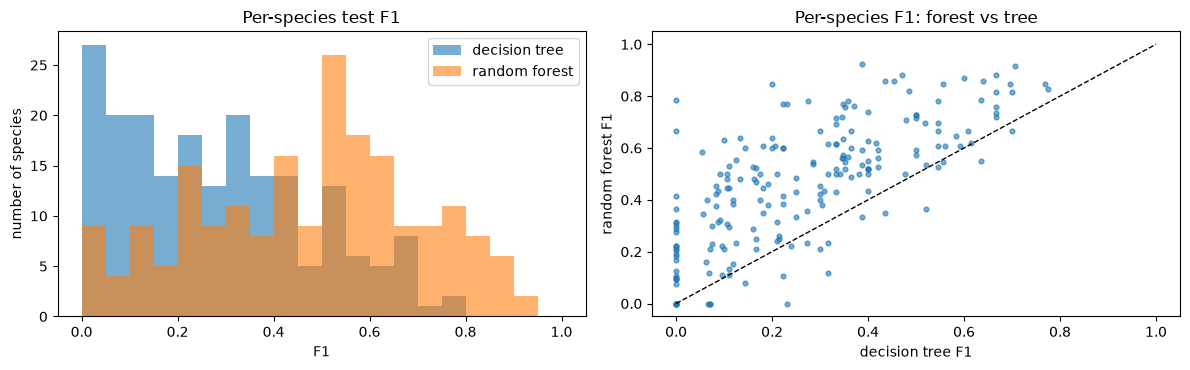

In [12]:
labels = class_names.loc[model.classes_].values
f1_forest = pd.Series(f1_score(y_test, y_pred, average=None, labels=model.classes_), index=labels)
f1_tree = pd.Series(f1_score(ya_test, tree_pred, average=None, labels=model.classes_), index=labels)

print('Best classified species (forest):');  print(f1_forest.nlargest(8).round(3).to_string())
print('\nWorst classified species (forest):'); print(f1_forest.nsmallest(8).round(3).to_string())
print(f'\nspecies improved over the tree: {(f1_forest > f1_tree).sum()} / {len(labels)}, '
      f'worse: {(f1_forest < f1_tree).sum()}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, 1, 21)
axes[0].hist(f1_tree, bins=bins, alpha=0.6, label='decision tree')
axes[0].hist(f1_forest, bins=bins, alpha=0.6, label='random forest')
axes[0].set(title='Per-species test F1', xlabel='F1', ylabel='number of species')
axes[0].legend()
axes[1].scatter(f1_tree, f1_forest, s=12, alpha=0.6)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set(title='Per-species F1: forest vs tree', xlabel='decision tree F1', ylabel='random forest F1')
plt.tight_layout()
plt.show()

## 10. Feature importance

**Impurity-based importance** (mean decrease in impurity) is computed during training, but it is known to be biased towards frequently split features. **Permutation importance** is more reliable: shuffle a feature and measure the drop in accuracy. Because each body part is one-hot encoded across many columns, we permute each **attribute group** as a whole (all columns of e.g. `has_wing_color` together). This asks how much accuracy is lost without the wing colour information.

Permutation importance is computed on the test set purely for interpretation. Nothing is tuned from it.

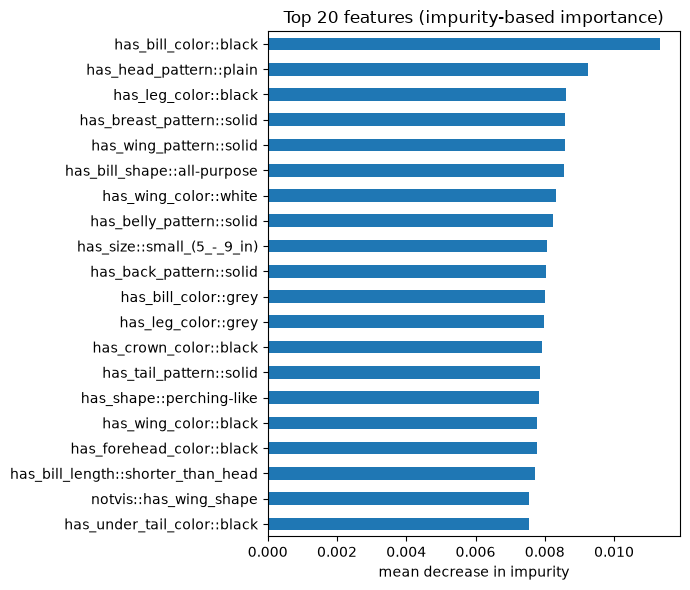

In [13]:
importances = pd.Series(model.feature_importances_, index=X_train.columns)

fig, ax = plt.subplots(figsize=(7, 6))
importances.nlargest(20).sort_values().plot.barh(ax=ax, color='tab:blue')
ax.set(title='Top 20 features (impurity-based importance)', xlabel='mean decrease in impurity')
plt.tight_layout()
plt.show()

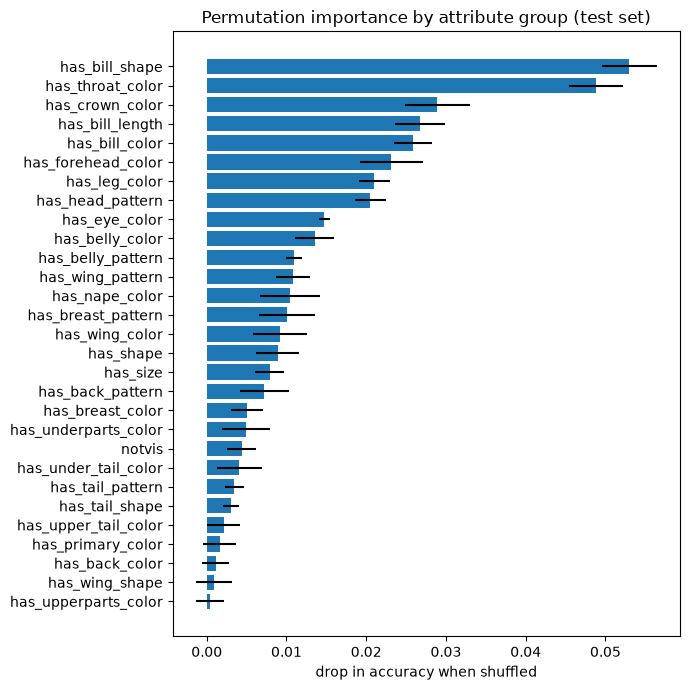

,accuracy drop,std
has_bill_shape,0.0530,0.0034
has_throat_color,0.0489,0.0034
has_crown_color,0.0289,0.0041
has_bill_length,0.0267,0.0031
has_bill_color,0.0259,0.0024
has_forehead_color,0.0232,0.0039
has_leg_color,0.0210,0.0019
has_head_pattern,0.0205,0.0019
has_eye_color,0.0148,0.0007
has_belly_color,0.0136,0.0024


In [14]:
rng = np.random.default_rng(RANDOM_STATE)
groups = X_test.columns.str.split('::').str[0]
base_acc = results['test_accuracy']
N_REPEATS = 5

drops = {}
for group in pd.unique(groups):
    cols = X_test.columns[groups == group]
    scores = []
    for _ in range(N_REPEATS):
        X_perm = X_test.copy()
        X_perm[cols] = X_test[cols].values[rng.permutation(len(X_test))]  # shuffle rows of the whole group together
        scores.append(base_acc - accuracy_score(y_test, model.predict(X_perm)))
    drops[group] = (np.mean(scores), np.std(scores))

group_perm = pd.DataFrame(drops, index=['accuracy drop', 'std']).T.sort_values('accuracy drop')
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(group_perm.index, group_perm['accuracy drop'], xerr=group_perm['std'], color='tab:blue')
ax.set(title='Permutation importance by attribute group (test set)', xlabel='drop in accuracy when shuffled')
plt.tight_layout()
plt.show()
group_perm.sort_values('accuracy drop', ascending=False).head(10).round(4)

**Reading the importances:**
- The ranking matches the official split. Bill shape and throat colour are clearly the most important groups, followed by crown colour, bill length, bill colour, forehead colour, leg colour and head pattern. The head and bill dominate.
- **The least important groups have two different explanations:**
  - **Often hidden:** tail shape/pattern, upper-tail colour, wing shape and back colour are the groups most often marked *not visible* (22–35% of images, `dataPrep.ipynb` §9). They are frequently missing or guessed.
  - **Redundant:** primary colour and upperparts colour are never marked not visible, yet still contribute almost nothing. They are summary colours that duplicate information already in the specific body-part colour groups, so shuffling them barely matters when those groups are intact.
- The 28 `notvis` flags together contribute about 0.4 points, consistent with variant C being only level with A (§6).

## 11. Comparison with the official split

The 80/20 split changes two things at once: there are **more training images** (33–48 vs 29–30 per species) and the **test set is different** (and smaller). To separate the two effects:
1. **Official split:** the tuned forest from `randomForest.ipynb` (variant C, gini, `max_depth=30`, `max_features='sqrt'`, `min_samples_leaf=2`, 750 trees) is refit here, to get its official-split numbers. Its CV accuracy is recomputed with the same 300-tree setting used in that notebook's grid search.
2. **80/20 test set, training capped at 30 images per species:** the configuration selected here is retrained on a random 30 images per species from the 80/20 training portion (5 repeats with different subsamples). This keeps the 80/20 test set but uses the official split's training size.

If (2) matches the official result, the improvement on 80/20 comes from the extra training data. If (2) matches the full 80/20 result, the 80/20 test set is simply easier.

In [15]:
OFFICIAL_VARIANT = 'C'
OFFICIAL_PARAMS = dict(criterion='gini', max_depth=30, max_features='sqrt', min_samples_leaf=2)

def official_split(name):
    df = pd.read_csv(DATA / f'cub_features_{name}.csv')
    features = [c for c in df.columns if c not in META_COLS]
    train, test = df[df.is_train == 1], df[df.is_train == 0]
    return train[features], train.class_id, test[features], test.class_id

Xo_train, yo_train, Xo_test, yo_test = official_split(OFFICIAL_VARIANT)
official_forest = RandomForestClassifier(n_estimators=750, random_state=RANDOM_STATE, n_jobs=-1, **OFFICIAL_PARAMS)
official_forest.fit(Xo_train, yo_train)
official_pred = official_forest.predict(Xo_test)
official_cv = cross_validate(RandomForestClassifier(n_estimators=SEARCH_N_ESTIMATORS, random_state=RANDOM_STATE,
                                                    n_jobs=-1, **OFFICIAL_PARAMS),
                             Xo_train, yo_train, cv=CV, scoring='accuracy')['test_score'].mean()

capped = []
for seed in range(5):
    sample = y_train.groupby(y_train).sample(n=30, random_state=seed).index
    capped_forest = RandomForestClassifier(n_estimators=FINAL_N_ESTIMATORS, random_state=RANDOM_STATE,
                                           n_jobs=-1, **BEST_PARAMS)
    capped_forest.fit(X_train.loc[sample], y_train.loc[sample])
    capped.append(accuracy_score(y_test, capped_forest.predict(X_test)))

split_comparison = pd.DataFrame({
    'official split': {'train images per species': '29-30', 'test images': len(yo_test),
                       'CV accuracy': official_cv, 'test accuracy': accuracy_score(yo_test, official_pred),
                       'test macro-F1': f1_score(yo_test, official_pred, average='macro')},
    '80/20, train capped at 30': {'train images per species': '30', 'test images': len(y_test),
                                  'CV accuracy': np.nan, 'test accuracy': np.mean(capped),
                                  'test macro-F1': np.nan},
    '80/20 split': {'train images per species': '33-48', 'test images': len(y_test),
                    'CV accuracy': results['cv_accuracy'], 'test accuracy': results['test_accuracy'],
                    'test macro-F1': results['test_f1_macro']},
}).T
print(f'capped-training test accuracy over 5 subsamples: {np.mean(capped):.3f} ± {np.std(capped):.3f}')
split_comparison

capped-training test accuracy over 5 subsamples: 0.465 ± 0.006


,train images per species,test images,CV accuracy,test accuracy,test macro-F1
official split,29-30,5794,0.445283,0.456334,0.434873
"80/20, train capped at 30",30,2358,NaN,0.464631,NaN
80/20 split,33-48,2358,0.474867,0.493215,0.471373


## 12. Summary

The headline numbers for the report:

In [16]:
summary = comparison.copy()
summary.loc['CV accuracy (train, 5-fold)'] = [tree_cv, results['cv_accuracy'], results['cv_accuracy'] - tree_cv]
summary.round(4)

,decision tree,random forest,improvement
test accuracy,0.2744,0.4932,0.2188
test macro-F1,0.2740,0.4714,0.1974
test top-5 accuracy,0.3863,0.7489,0.3626
"CV accuracy (train, 5-fold)",0.2719,0.4749,0.2030


In [17]:
print('selected variant:', BEST_VARIANT)
print('selected hyperparameters:', {**BEST_PARAMS, 'n_estimators': FINAL_N_ESTIMATORS})

selected variant: C
selected hyperparameters: {'class_weight': 'balanced_subsample', 'criterion': 'gini', 'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 1000}


**Findings (with `RANDOM_STATE = 42`, `SPLIT_SEED = 42`):**
- **Test accuracy is 49.3%** (macro-F1 0.471, top-5 74.9%), against 45.6% on the official split: **+3.7 points**.
- **About three quarters of that gain comes from the extra training data** (§11). Training on just 30 images per species, but testing on the 80/20 test set, gives 46.5% (±0.6). That's 0.9 points above the official split (a slightly easier or different test set). The remaining **2.8 points come from the extra 3–18 training images per species**. That is more than the single tree gained (1.9 points): the forest benefits more from extra data, because it overfits less and can make use of it.
- **The forest again clearly beats the decision tree** on the same 80/20 test set: 49.3% vs 27.4% (+21.9 points). McNemar's test gives 614 images only the forest gets right vs 98 only the tree gets right (p ≈ 4e-92). 176 of 200 species improve.
- **Hyperparameters:** gini, `max_features='sqrt'`, fully grown trees (`min_samples_leaf=1`, depth 30 or unlimited). The top configurations are within about 0.5 points of each other, so the forest is again robust to tuning.
- **Tree count:** the OOB curve is still rising very slightly at 1,000 trees (0.473 → 0.475 from 750 to 1,000), so the rule selected the largest count tested. The remaining gain from more trees is a fraction of a point.
- **`class_weight='balanced_subsample'`** was selected for every variant, but its lead over no weighting is about 0.25 points, within the fold noise (about 0.6–1.3 points). Like the tree, the forest is not meaningfully affected by the mild 33–48 imbalance.
- **Feature variants:** C (0.475) ≈ A (0.473) > **B (0.455)**. C and A are tied within noise, but **B is clearly worse for the forest**, by about 2 points, well beyond the fold std (about 0.5–1.0). The same ordering appeared on the official split (B 0.435 vs A 0.444). Encoding "not visible" as −1 inside the colour columns seems to blur the features for the forest, while separate flags (C) are harmless but add nothing.
- **Errors are lookalike species:** the two shrikes, grackle vs starling, grebes, terns, crows and ravens, and gulls. With only 8–12 test images per species these counts are small and noisy.
- **Recommendation:** the 80/20 split gives a real gain of about 3 points for the forest, mostly from more training data, at the cost of a smaller, noisier test set and no comparability with published results. Whichever split the team chooses, all four models must use the same one.


## 13. Limitations

- **Single seed and single split:** all results use `RANDOM_STATE = 42` and one fixed 80/20 split (`SPLIT_SEED = 42` in `dataPrep.ipynb`). A different split would give somewhat different numbers.
- **Smaller test set:** 2,358 test images (8–12 per species), against 5,794 on the official split. Test accuracy has a standard error of about ±1.0 point (vs about ±0.65), and the per-species F1 values in §9 rest on very few images each.
- **Not comparable with published results:** work on CUB-200-2011 normally reports the official split.
- **Tree count used in the search:** the grid search used 300 trees, while the final model uses the count chosen in §3. This assumes the ranking of configurations doesn't change with more trees, which is reasonable given the OOB plateau, but it wasn't verified.
- **Permutation importance on the test set:** this describes this particular (small) test set. Nothing was tuned on it.
- **Label noise and identical vectors:** a single annotator per image, and 16 groups of identical feature vectors with different species, put a ceiling on any tabular model.
- **Untested cleaning option:** the "drop guessing positives" switch in `dataPrep.ipynb` was not evaluated.
